In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [10]:
def laguerre_func(t, n, beta=2.0, sigma=4.0):
    if n < 0 or beta < 0 or beta > sigma:
        raise ValueError("Некоректні вхідні дані")
    
    base_multiplier = np.exp(t * (beta / -2.0)) * np.sqrt(sigma)
    
    if n == 0:
        return base_multiplier
    if n == 1:
        return base_multiplier * (1 - sigma * t)
    
    l_prev2 = base_multiplier                  
    l_prev1 = base_multiplier * (1 - sigma * t) 
    
    for i in range(2, n + 1):
        l_current = ((2 * i - 1 - sigma * t) * l_prev1 / i) - ((i - 1) * l_prev2 / i)
        l_prev2 = l_prev1
        l_prev1 = l_current
        
    return l_prev1

In [11]:
def tabulate_laguerre(n, T, step, beta=2.0, sigma=4.0):
    if T <= 0 or step <= 0:
        raise ValueError("T > 0, step > 0")
        
    results = []
    
    num_steps = int(np.floor(T / step) + 1) 
    
    for i in range(num_steps):
        t = i * step
        val = laguerre_func(t, n, beta, sigma)
        results.append((t, val))
        
    return results

In [12]:
def run_experiment(N=20, epsilon=1e-3, step=0.1, beta=2.0, sigma=4.0):
    t = 0.0
    while True:
        condition_met = True
        for n in range(N + 1):
            if abs(laguerre_func(t, n, beta, sigma)) >= epsilon:
                condition_met = False
                break
        
        if condition_met and t > 0:
            return t
        
        t += step

In [14]:
n_val = int(input("Введіть порядок n = "))
T_val = float(input("Введіть кінець відрізка T = "))
step_val =float(input("Введіть крок = "))

table_data = tabulate_laguerre(n_val, T_val, step_val)

df = pd.DataFrame(table_data)
df.index =  range(1, len(df) + 1)
df.columns = ["t", "L_t"]
df

Введіть порядок n =  10
Введіть кінець відрізка T =  20
Введіть крок =  1


,t,L_t
1,0.0,2.000000
2,1.0,1.014802
3,2.0,-0.957821
4,3.0,-0.910961
5,4.0,-3.394134
6,5.0,43.497595
7,6.0,-111.595661
8,7.0,-237.196686
9,8.0,656.268874
10,9.0,3276.293226


In [15]:
N_exp = 20
epsilon = 1e-3

T_found = run_experiment(N=N_exp, epsilon=epsilon, step=0.1)
values = np.array([(n,abs(laguerre_func(T_found, n))) for n in range(N_exp + 1)])


print(f"точка T = {T_found:.1f}")
df = pd.DataFrame(values)
df.index = range(1, len(df)+1)
df.columns = ["n","L_n(T)"]
df["n"] = df["n"].astype(int)
df


точка T = 79.1


,n,L_n(T)
1,0,8.878436e-35
2,1,2.800259e-32
3,2,4.387961e-30
4,3,4.554517e-28
5,4,3.522590e-26
6,5,2.165324e-24
7,6,1.101856e-22
8,7,4.773904e-21
9,8,1.797604e-19
10,9,5.975786e-18


In [16]:
def Riemann_sum(steps, delta_t, k, f, beta=2.0, sigma=4.0,):
    I_prev = 0.0
    for i in range(steps):
        t = i * delta_t
        val = f(t)
        l_k = laguerre_func(t, k, beta, sigma)
        e = np.exp(-(sigma - beta) * t)
        I_prev += val * l_k * e

    return I_prev*delta_t

In [17]:
def transformation(f, T, k, steps=100, beta=2.0, sigma=4.0, epsilon=1e-3):
    delta_t = T / steps
    
    I_prev = Riemann_sum(steps, delta_t, k, f, beta=2.0, sigma=4.0)
    
    while True:
        steps *= 2  
        delta_t = T / steps
        I_current = Riemann_sum(steps, delta_t, k, f, beta=2.0, sigma=4.0)
        
        if abs(I_current - I_prev) < epsilon:
            return I_current
            
        I_prev = I_current

In [18]:
result = transformation(
    k=2,
    T=50.0,
    steps=10000,
    f=lambda t: laguerre_func(t, n=3, beta=2.0, sigma=4.0),
    beta=2.0,
    sigma=4.0
)

print(f"Отриманий коефіцієнт f_k: {result}")

Отриманий коефіцієнт f_k: 0.0006257812496867608


In [23]:
def f_task5(t):
    if 0 <= t <= 2 * np.pi:
        return np.sin(t - np.pi / 2) + 1
    else:
        return 0.0

N = 20
T_integration = 2 * np.pi
coefficients_f = np.array([ transformation(
        k=k,
        T=T_integration,
        f=f_task5,
        steps=1000, 
        beta=2.0,
        sigma=4.0,
        epsilon=1e-4
    )for k in range(N + 1)])
k = np.arange(N+1)
df = pd.DataFrame({"k":k, "f_k":coefficients_f})
df.index = range(1, len(df)+1)
df["k"] = df["k"].astype(int)
df

,k,f_k
1,0,0.066667
2,1,-0.182222
3,2,0.178074
4,3,-0.074290
5,4,0.007264
6,5,0.007588
7,6,-0.003097
8,7,-0.000615
9,8,0.000800
10,9,-0.000026


In [28]:
def inverse_laguerre_transform(h_seq, t, beta=2.0, sigma=4.0):
    result = 0.0
    for k in range(len(h_seq)):
        result += np.array(h_seq[k] * laguerre_func(t, k, beta, sigma))
    
    return result.sum()

t_test = np.pi

approx_val = inverse_laguerre_transform(coefficients_f, t_test)
exact_val = f_task5(t_test)

print(f"Тестування оберненого перетворення у точці t = {t_test:.5f}:")
print(f"Точне значення функції:      f(t)   = {exact_val:.5f}")
print(f"Наближене значення (оберн. ПЛ): h^N(t) = {approx_val:.5f}")
print(f"Абсолютна похибка:                   {abs(exact_val - approx_val):.5e}")

Тестування оберненого перетворення у точці t = 3.14159:
Точне значення функції:      f(t)   = 2.00000
Наближене значення (оберн. ПЛ): h^N(t) = 1.99994
Абсолютна похибка:                   6.08162e-05


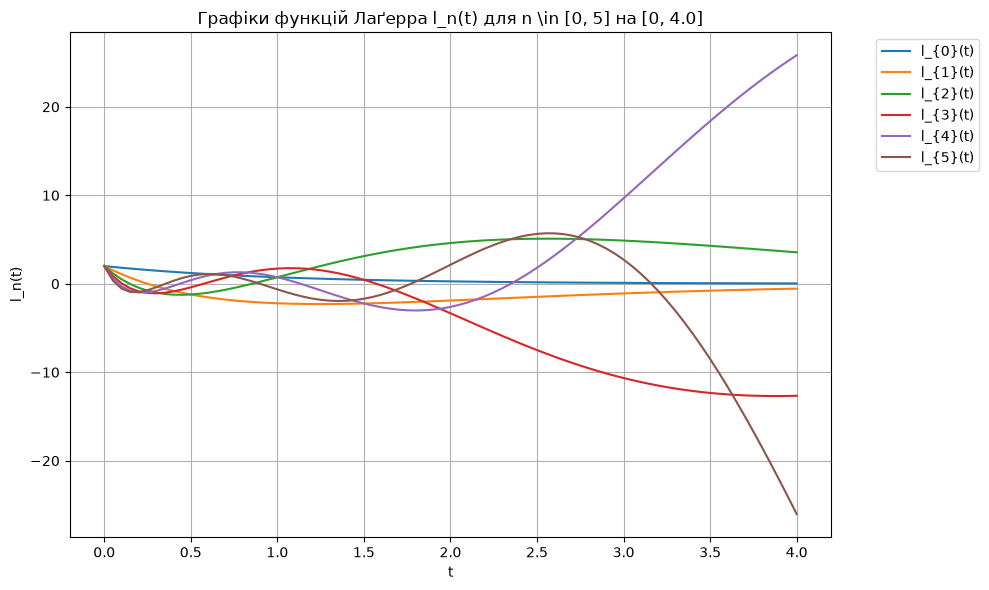

In [29]:
def plot_laguerre(N, T, step=0.1, beta=2.0, sigma=4.0):
    plt.figure(figsize=(10, 6))
    
    for n in range(N + 1):
        data = tabulate_laguerre(n, T, step, beta=beta, sigma=sigma)
        
        t_vals = [pt[0] for pt in data]
        y_vals = [pt[1] for pt in data]
        
        plt.plot(t_vals, y_vals, label=f"l_{{{n}}}(t)")
    
    plt.title(f"Графіки функцій Лаґерра l_n(t) для n \\in [0, {N}] на [0, {T}]")
    plt.xlabel("t")
    plt.ylabel("l_n(t)")
    plt.grid(True)
    
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
    
plot_laguerre(N=5, T=4.0, step=0.05)

In [30]:
def approximate_function(coeffs, N, t_vals, beta=2.0, sigma=4.0):

    h = coeffs[:N + 1]
    coef = np.array([inverse_laguerre_transform(h, t, beta, sigma) for t in t_vals])
    return coef

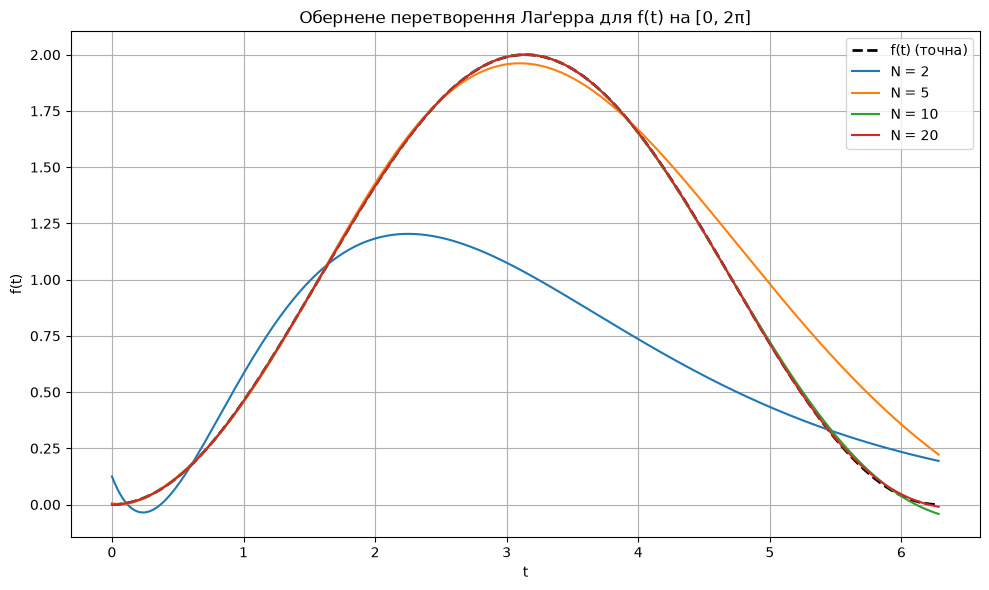

In [32]:
def plot_approximation(f, coeffs, N_list, T=2 * np.pi, points=300):
    t_vals = np.linspace(0, T, points + 1)
    exact = np.array([f(t) for t in t_vals])
    plt.figure(figsize=(10, 6))
    plt.plot(t_vals, exact, "k--", linewidth=2, label="f(t) (точна)")
    for N in N_list:
        approx = approximate_function(coeffs, N, t_vals)
        plt.plot(t_vals, approx, label=f"N = {N}")

    plt.title("Обернене перетворення Лаґерра для f(t) на [0, 2π]")
    plt.xlabel("t")
    plt.ylabel("f(t)")
    plt.grid(True)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

plot_approximation(f_task5, coefficients_f, N_list=[2, 5, 10, 20])